# LAB 3 – Text Generation Using GPT-2

**Course:** ETMMGA304 - Generative AI and Its Applications (MCA AI/ML)

**Name:** Anuj

**Roll No.:** 2501940039

**Program:** MCA (AI & ML)

**Date:** 22-11-2026

## Aim
To generate text using GPT-2, compare different decoding strategies,
fine-tune the last Transformer block, and evaluate the model on
held-out topics.bold text

## Import **libraries**

In [1]:
from pathlib import Path
import random
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

out = Path("lab_outputs")
out.mkdir(exist_ok=True)

print("Device:", device)
print("PyTorch version:", torch.__version__)

Device: cuda
PyTorch version: 2.14.1+cu130


In [12]:
%pip install -q --upgrade "huggingface-hub>=1.32.0,<3.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tokenizers 0.22.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.4.0 which is incompatible.
transformers 4.57.6 requires huggingface-hub<1.0,>=0.34.0, but you have huggingface-hub 2.4.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


## Install **Transformers**

In [2]:
%pip install -q "transformers>=4.51,<5"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## Load pretrained GPT-2 **model**

In [3]:
from transformers import AutoTokenizer, AutoModelForCausalLM

model_id = "openai-community/gpt2"

tokenizer = AutoTokenizer.from_pretrained(model_id)

tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(model_id).to(device)

model.config.pad_token_id = tokenizer.eos_token_id

model.eval()

print("GPT-2 model loaded successfully!")
print("Model:", model_id)
print("Device:", device)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2 model loaded successfully!
Model: openai-community/gpt2
Device: cuda


## Text generation using different decoding **strategies**

In [4]:
def continue_text(
    prompt,
    generation_model,
    sample=False,
    temperature=0.8,
    seed=42
):
    torch.manual_seed(seed)

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(device)

    options = {
        "do_sample": sample,
        "max_new_tokens": 45,
        "pad_token_id": tokenizer.eos_token_id
    }

    if sample:
        options.update(
            temperature=temperature,
            top_p=0.9
        )

    generation_model.eval()

    with torch.no_grad():
        tokens = generation_model.generate(
            **inputs,
            **options
        )

    generated_text = tokenizer.decode(
        tokens[0, inputs.input_ids.size(1):],
        skip_special_tokens=True
    ).strip()

    return generated_text


prompts = [
    "A story about a robot begins like this:",
    "In a school library, a tiny robot found a lost book. It"
]

generation_results = []

for prompt_index, prompt in enumerate(prompts):

    print("\n" + "=" * 70)
    print("PROMPT:", prompt)
    print("=" * 70)

    # Greedy decoding
    greedy_output = continue_text(
        prompt,
        model,
        sample=False
    )

    print("\nGREEDY:")
    print(greedy_output)

    generation_results.append({
        "Prompt": prompt,
        "Decoding": "Greedy",
        "Temperature": "N/A",
        "Seed": "N/A",
        "Generated Text": greedy_output
    })

    # Sampling with different temperatures and seeds
    for temp in (0.6, 1.0):

        for seed in (42, 43):

            output = continue_text(
                prompt,
                model,
                sample=True,
                temperature=temp,
                seed=seed
            )

            print(f"\nTemperature: {temp}, Seed: {seed}")
            print(output)

            generation_results.append({
                "Prompt": prompt,
                "Decoding": "Sampling",
                "Temperature": temp,
                "Seed": seed,
                "Generated Text": output
            })


PROMPT: A story about a robot begins like this:

GREEDY:
A robot is a robot that is programmed to do something. It is programmed to do something. It is programmed to do something. It is programmed to do something. It is programmed to do something. It is programmed

Temperature: 0.6, Seed: 42
I was in my basement, and a guy came in, and he said, "Hey, we're going to be building a robot. Let's go, and we're going to be building a robot that's

Temperature: 0.6, Seed: 43
A robot is a computer program that communicates with humans via a computer program. The robot's job is to create and control a computer program. The robot's job is to control a computer program.

That's

Temperature: 1.0, Seed: 42
It was supposed to be something big, but it never happened. It was called a toy, but no one liked it because it wasn't the most interesting thing in the universe, even though it was a real thing. But

Temperature: 1.0, Seed: 43
A robotic girl runs into a strange, alien world called "Rome."

Rom

## Display generated text **results**

In [5]:
results_df = pd.DataFrame(generation_results)

pd.set_option("display.max_colwidth", None)

display(results_df)

,Prompt,Decoding,Temperature,Seed,Generated Text
0,A story about a robot begins like this:,Greedy,N/A,N/A,A robot is a robot that is programmed to do something. It is programmed to do something. It is programmed to do something. It is programmed to do something. It is programmed to do something. It is programmed
1,A story about a robot begins like this:,Sampling,0.6,42,"I was in my basement, and a guy came in, and he said, ""Hey, we're going to be building a robot. Let's go, and we're going to be building a robot that's"
2,A story about a robot begins like this:,Sampling,0.6,43,A robot is a computer program that communicates with humans via a computer program. The robot's job is to create and control a computer program. The robot's job is to control a computer program.\n\nThat's
3,A story about a robot begins like this:,Sampling,1.0,42,"It was supposed to be something big, but it never happened. It was called a toy, but no one liked it because it wasn't the most interesting thing in the universe, even though it was a real thing. But"
4,A story about a robot begins like this:,Sampling,1.0,43,"A robotic girl runs into a strange, alien world called ""Rome.""\n\nRome's ""Sculpture of Chaos"" is where she's found. She asks for a special artifact from the """
5,"In a school library, a tiny robot found a lost book. It",Greedy,N/A,N/A,"was a book that had been lost for years.\n\n""I was like, 'Oh my God, this is so weird,'"" said the boy, who asked not to be identified. ""I was like, 'Oh"
6,"In a school library, a tiny robot found a lost book. It",Sampling,0.6,42,"was the only book in the library, and it was the only one that had been lost in the war. The robot was not the only one who had lost his book. The other two books were the ones that had been"
7,"In a school library, a tiny robot found a lost book. It",Sampling,0.6,43,"was a book with a name: ""The Book of the Dead.""\n\nThe book was the book of the dead. The book of the dead.\n\nA few days later, the robot went missing."
8,"In a school library, a tiny robot found a lost book. It",Sampling,1.0,42,"was the only book in its collection, and had never been in a class of its own, let alone the library's. A dozen books stood on the shelf, each a different class of books. One was named after him"
9,"In a school library, a tiny robot found a lost book. It",Sampling,1.0,43,"knew that the book belonged to a man named David, who had been captured by aliens with a key. He thought that he was going to be able to rescue David's lost companion, but he would need an amazing source of"


## Decoding observation **table**

In [6]:
observation_rows = []

for result in generation_results:

    observation_rows.append({
        "Prompt": (
            "Robot story"
            if "robot" in result["Prompt"].lower()
            else "Library story"
        ),
        "Decoding & Seed": (
            result["Decoding"]
            if result["Decoding"] == "Greedy"
            else f'{result["Temperature"]} & {result["Seed"]}'
        ),
        "Coherence (0-2)": "",
        "Relevance (0-2)": "",
        "Creativity (0-2)": "",
        "Generated Excerpt": result["Generated Text"]
    })

observation_df = pd.DataFrame(observation_rows)

display(observation_df)

observation_df.to_csv(
    out / "decoding_observations.csv",
    index=False
)

,Prompt,Decoding & Seed,Coherence (0-2),Relevance (0-2),Creativity (0-2),Generated Excerpt
0,Robot story,Greedy,,,,A robot is a robot that is programmed to do something. It is programmed to do something. It is programmed to do something. It is programmed to do something. It is programmed to do something. It is programmed
1,Robot story,0.6 & 42,,,,"I was in my basement, and a guy came in, and he said, ""Hey, we're going to be building a robot. Let's go, and we're going to be building a robot that's"
2,Robot story,0.6 & 43,,,,A robot is a computer program that communicates with humans via a computer program. The robot's job is to create and control a computer program. The robot's job is to control a computer program.\n\nThat's
3,Robot story,1.0 & 42,,,,"It was supposed to be something big, but it never happened. It was called a toy, but no one liked it because it wasn't the most interesting thing in the universe, even though it was a real thing. But"
4,Robot story,1.0 & 43,,,,"A robotic girl runs into a strange, alien world called ""Rome.""\n\nRome's ""Sculpture of Chaos"" is where she's found. She asks for a special artifact from the """
5,Robot story,Greedy,,,,"was a book that had been lost for years.\n\n""I was like, 'Oh my God, this is so weird,'"" said the boy, who asked not to be identified. ""I was like, 'Oh"
6,Robot story,0.6 & 42,,,,"was the only book in the library, and it was the only one that had been lost in the war. The robot was not the only one who had lost his book. The other two books were the ones that had been"
7,Robot story,0.6 & 43,,,,"was a book with a name: ""The Book of the Dead.""\n\nThe book was the book of the dead. The book of the dead.\n\nA few days later, the robot went missing."
8,Robot story,1.0 & 42,,,,"was the only book in its collection, and had never been in a class of its own, let alone the library's. A dozen books stood on the shelf, each a different class of books. One was named after him"
9,Robot story,1.0 & 43,,,,"knew that the book belonged to a man named David, who had been captured by aliens with a key. He thought that he was going to be able to rescue David's lost companion, but he would need an amazing source of"


## Fine-tune the last Transformer **block**

In [7]:
examples = [
    ("graphs", "Sketch a graph, then mark a path through three vertices."),
    ("Python loops", "Trace a loop by writing the counter after each step."),
    ("fractions", "Draw equal parts and label the fraction you shaded."),
    ("sets", "Draw a Venn diagram and label the intersection."),
    ("sorting", "Sort five values by hand and record each swap."),
    ("probability", "List the outcomes of two coin tosses before counting.")
]

# Load a fresh copy of GPT-2
tuned = AutoModelForCausalLM.from_pretrained(model_id).to(device)

# Freeze all model parameters
tuned.requires_grad_(False)

# Unfreeze only the last Transformer block
tuned.transformer.h[-1].requires_grad_(True)

# Optimizer
opt = torch.optim.AdamW(
    tuned.transformer.h[-1].parameters(),
    lr=2e-5
)

print("Trainable parameters:")
print(
    sum(p.numel() for p in tuned.parameters() if p.requires_grad)
)

print("\nStarting fine-tuning...")

training_losses = []

for epoch in range(3):

    tuned.train()
    epoch_losses = []

    for topic, answer in examples:

        prefix = tokenizer.encode(
            f"Topic: {topic}\nStudy tip:"
        )

        target = tokenizer.encode(
            " " + answer
        ) + [tokenizer.eos_token_id]

        input_ids = torch.tensor(
            [prefix + target],
            device=device
        )

        labels = torch.tensor(
            [[-100] * len(prefix) + target],
            device=device
        )

        opt.zero_grad()

        loss = tuned(
            input_ids=input_ids,
            labels=labels
        ).loss

        loss.backward()

        opt.step()

        epoch_losses.append(loss.item())

    avg_loss = sum(epoch_losses) / len(epoch_losses)
    training_losses.append(avg_loss)

    print(
        f"Epoch {epoch + 1}/3 - Average Loss: {avg_loss:.4f}"
    )

# Save fine-tuned model
tuned.save_pretrained(out / "study_tip_gpt2")
tokenizer.save_pretrained(out / "study_tip_gpt2")

print("\nFine-tuning completed!")

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Trainable parameters:
7087872

Starting fine-tuning...
Epoch 1/3 - Average Loss: 5.1594
Epoch 2/3 - Average Loss: 4.8761
Epoch 3/3 - Average Loss: 5.1777

Fine-tuning completed!


## Plot fine-tuning **loss**

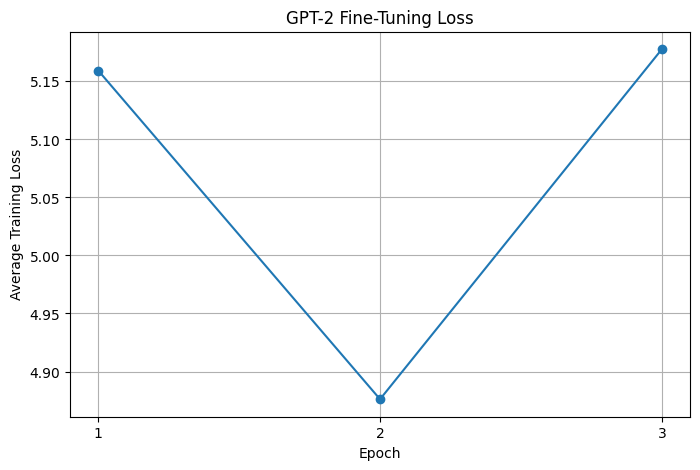

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(training_losses) + 1),
    training_losses,
    marker="o"
)

plt.title("GPT-2 Fine-Tuning Loss")
plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.xticks([1, 2, 3])
plt.grid(True)

plt.savefig(
    out / "fine_tuning_loss.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## Evaluate on held-out **topics**

In [9]:
held_out = [
    "recursion",
    "matrices",
    "binary search"
]

print("Comparing Base GPT-2 and Fine-Tuned GPT-2")
print("=" * 70)

evaluation_results = []

for topic in held_out:

    prompt = f"Topic: {topic}\nStudy tip:"

    # Base model output
    base_output = continue_text(
        prompt,
        model,
        sample=False
    )

    # Fine-tuned model output
    tuned_output = continue_text(
        prompt,
        tuned,
        sample=False
    )

    print(f"\nTOPIC: {topic}")

    print("\nBASE MODEL:")
    print(base_output)

    print("\nFINE-TUNED MODEL:")
    print(tuned_output)

    evaluation_results.append({
        "Topic": topic,
        "Base GPT-2 Output": base_output,
        "Fine-Tuned GPT-2 Output": tuned_output
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df)

evaluation_df.to_csv(
    out / "held_out_evaluation.csv",
    index=False
)

Comparing Base GPT-2 and Fine-Tuned GPT-2

TOPIC: recursion

BASE MODEL:
Use the recursion keyword to define a new type of recursion.

Example:

class Recursion { public: Recursion(int i) { return i; } public: Recursion(int i)

FINE-TUNED MODEL:
Use the recursion keyword to define a new type of recursion.

Example:

class Recursion { public: Recursion(int x, int y) { return x + y; } public: Rec

TOPIC: matrices

BASE MODEL:
Use the matrices to create a matrix of the same size as the input.

The following matrix is a matrix of the same size as the input.

The following matrix is a matrix of the same size as

FINE-TUNED MODEL:
Use the matrices to create a matrix of the same size as the input.

The following matrix is a matrix of the same size as the input.

The following matrix is a matrix of the same size as

TOPIC: binary search

BASE MODEL:
Use the search box to find the search term you want to search for.

Study tip: Use the search box to find the search term you want to search for.


,Topic,Base GPT-2 Output,Fine-Tuned GPT-2 Output
0,recursion,Use the recursion keyword to define a new type of recursion.\n\nExample:\n\nclass Recursion { public: Recursion(int i) { return i; } public: Recursion(int i),"Use the recursion keyword to define a new type of recursion.\n\nExample:\n\nclass Recursion { public: Recursion(int x, int y) { return x + y; } public: Rec"
1,matrices,Use the matrices to create a matrix of the same size as the input.\n\nThe following matrix is a matrix of the same size as the input.\n\nThe following matrix is a matrix of the same size as,Use the matrices to create a matrix of the same size as the input.\n\nThe following matrix is a matrix of the same size as the input.\n\nThe following matrix is a matrix of the same size as
2,binary search,Use the search box to find the search term you want to search for.\n\nStudy tip: Use the search box to find the search term you want to search for.\n\nStudy tip: Use the search box to,Use the search box to find the search term you want to search for.\n\nStudy tip: Use the search box to find the search term you want to search for.\n\nStudy tip: Use the search box to


## Save model and **results**

In [10]:
# Save the base model information
model.save_pretrained(out / "base_gpt2")
tokenizer.save_pretrained(out / "base_gpt2")

# Save generated text
results_df.to_csv(
    out / "generated_text.csv",
    index=False
)

# Save evaluation results
evaluation_df.to_csv(
    out / "held_out_evaluation.csv",
    index=False
)

print("All outputs saved successfully!")

All outputs saved successfully!


## Download all output **files**

In [11]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "Lab3_Anuj_2501940039",
    "zip",
    out
)

print("ZIP file created:", zip_path)

files.download(zip_path)

ZIP file created: /content/Lab3_Anuj_2501940039.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>